In [ ]:
# Cell 1: Total clean-up of any file/folder shadow and proper reinstall
import os
import shutil

# Remove any accidental local files shadowing OpenCV
if os.path.exists('cv2.py'):
    os.remove('cv2.py')
if os.path.isdir('cv2'):
    shutil.rmtree('cv2')

# Reinstall a pristine build of OpenCV
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless
!pip install -q opencv-python pillow-heif

# Verify import and path
import cv2
print("OpenCV Version:", cv2.__version__)
print("Cascade path:", cv2.data.haarcascades)

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 81.7 MB/s eta 0:00:00
OpenCV Version: 5.0.0
Cascade path: /usr/local/lib/python3.13/dist-packages/cv2/data/


In [ ]:
!pip install -q opencv-python==4.10.0.84

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 9.4 MB/s eta 0:00:00


In [ ]:
# Force-uninstall all variants and install stable OpenCV 4.x
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless
!pip install --no-cache-dir opencv-python==4.10.0.84 pillow-heif

# Verify it worked
import cv2
print("New OpenCV Version:", cv2.__version__)
print("Has CascadeClassifier:", hasattr(cv2, 'CascadeClassifier'))

Found existing installation: opencv-python 4.10.0.84
Uninstalling opencv-python-4.10.0.84:
  Successfully uninstalled opencv-python-4.10.0.84
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 156.2 MB/s eta 0:00:00
New OpenCV Version: 4.10.0
Has CascadeClassifier: True


In [ ]:
!pip install -q opencv-contrib-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 MB 9.3 MB/s eta 0:00:00


In [ ]:
import cv2
print("Has CascadeClassifier:", hasattr(cv2, 'CascadeClassifier'))

Has CascadeClassifier: True


In [ ]:
# Cell 2: Fresh Full Dataset Split (Processes all classes from scratch)
import os
import random
import shutil
import cv2
import numpy as np
from PIL import Image
import pillow_heif
from google.colab import drive

pillow_heif.register_heif_opener()
drive.mount('/content/drive', force_remount=True)

SOURCE_DIR = '/content/drive/MyDrive/rgb_dataset/rgb'
OUTPUT_DIR = '/content/drive/MyDrive/rgb_dataset/dataset_split'

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Wipe the old split directory to ensure a clean, uniform re-split of all classes
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)
    print("Cleared old dataset split directory.")

# Safe Haar Cascade initialization
cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
face_cascade = cv2.CascadeClassifier(cascade_path)

def detect_and_crop_face(image_path, save_path):
    try:
        pil_img = Image.open(image_path).convert('RGB')
        img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
    except Exception as e:
        print(f"Skipping {image_path} due to read error: {e}")
        return

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

    if len(faces) > 0:
        (x, y, w, h) = faces[0]
        margin = int(0.2 * w)
        h_img, w_img, _ = img.shape

        start_x = max(0, x - margin)
        start_y = max(0, y - margin)
        end_x = min(w_img, x + w + margin)
        end_y = min(h_img, y + h + margin)

        cropped_img = img[start_y:end_y, start_x:end_x]
        cv2.imwrite(save_path, cropped_img)
    else:
        cv2.imwrite(save_path, img)

if os.path.exists(SOURCE_DIR):
    random.seed(42)
    for class_name in os.listdir(SOURCE_DIR):
        class_dir = os.path.join(SOURCE_DIR, class_name)
        if not os.path.isdir(class_dir):
            continue

        print(f"Processing person folder: '{class_name}'...")
        for split in ['train', 'val', 'test']:
            os.makedirs(os.path.join(OUTPUT_DIR, split, class_name), exist_ok=True)

        images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.heic', '.jpeg', '.jpg', '.png'))]
        random.shuffle(images)

        n_total = len(images)
        n_train = int(n_total * TRAIN_RATIO)
        n_val = int(n_total * VAL_RATIO)

        splits = {
            'train': images[:n_train],
            'val': images[n_train:n_train + n_val],
            'test': images[n_train + n_val:]
        }

        for split_name, img_list in splits.items():
            for img_name in img_list:
                src_path = os.path.join(class_dir, img_name)
                base_name = os.path.splitext(img_name)[0]
                dst_path = os.path.join(OUTPUT_DIR, split_name, class_name, f"{base_name}.jpg")
                detect_and_crop_face(src_path, dst_path)

    print("All 7 classes successfully re-split and saved to Google Drive at:", OUTPUT_DIR)
else:
    print(f"Error: Could not find path '{SOURCE_DIR}'.")

Mounted at /content/drive
Cleared old dataset split directory.
Processing person folder: 'surej'...
Processing person folder: 'nikhil'...
Processing person folder: 'Akshath'...
Processing person folder: 'Vidyarth'...
Processing person folder: 'nithes'...
Processing person folder: 'tarun'...
Processing person folder: 'pravesh'...
All 7 classes successfully re-split and saved to Google Drive at: /content/drive/MyDrive/rgb_dataset/dataset_split


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_uism_embedding_network(input_shape=(128, 128, 3), embedding_dim=128):
    inputs = layers.Input(shape=input_shape)

    # Preprocessing and normalization
    x = layers.Rescaling(1./255)(inputs)

    # Residual-style feature extraction blocks tuned for manifold mapping
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    # Dense projection into the latent manifold space
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.4)(x)

    # Raw embedding output
    raw_embedding = layers.Dense(embedding_dim, activation=None, name="manifold_projection")(x)

    # L2 Normalization projects all vectors onto a hyperspherical manifold surface
    # (essential for stable cosine/Euclidean distance matching)
    normalized_embedding = layers.Lambda(
        lambda v: tf.math.l2_normalize(v, axis=1),
        name="unit_hypersphere_embedding"
    )(raw_embedding)

    return models.Model(inputs, normalized_embedding, name="UISM_Net")

uism_model = build_uism_embedding_network()
uism_model.summary()

Model: "UISM_Net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ manifold_projection (Dense)     │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unit_hypersphere_embedding      │ (None, 128)            │             0 │
│ (Lambda)                        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,064 (625.25 KB)

 Trainable params: 159,616 (623.50 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Run this to reload your datasets before running your evaluation loop
TRAIN_DIR = '/content/drive/MyDrive/rgb_dataset/dataset_split/train'
VAL_DIR = '/content/drive/MyDrive/rgb_dataset/dataset_split/val'
TEST_DIR = '/content/drive/MyDrive/rgb_dataset/dataset_split/test'

BATCH_SIZE = 32
IMG_SIZE = (128, 128)

train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names

NameError: name 'tf' is not defined

In [ ]:
# If you need to reload a saved model from your Drive, run this:
import tensorflow as tf

model_path = '/content/drive/MyDrive/rgb_dataset/saved_models/rgb_face_cnn_model.keras'
if tf.io.gfile.exists(model_path):
    model = tf.keras.models.load_model(model_path)
    print("Model successfully loaded from Google Drive!")
else:
    print("Saved model not found. Please run your model creation and training cell first.")

Model successfully loaded from Google Drive!


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Found 94 files belonging to 7 classes.
Found 18 files belonging to 7 classes.
Found 27 files belonging to 7 classes.
Classes: ['Akshath', 'Vidyarth', 'nikhil', 'nithes', 'pravesh', 'surej', 'tarun']
train Akshath 11
train Vidyarth 15
train nikhil 11
train nithes 13
train pravesh 15
train surej 9
train tarun 20
val Akshath 2
val Vidyarth 3
val nikhil 2
val nithes 2
val pravesh 3
val surej 2
val tarun 4
test Akshath 3
test Vidyarth 4
test nikhil 4
test nithes 4
test pravesh 4
test surej 3
test tarun 5
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 541ms/step - accuracy: 0.0745 - loss: 1.9624 - val_accuracy: 0.1667 - val_loss: 1.9697 - learning_rate: 1.0000e-04
Epoch 2/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 235ms/step - accuracy: 0.1702 - loss: 1.9364 - val_accuracy: 0.3333 - val_loss: 1.9397 - learning_rate: 1.0000e-04
Epoch 3/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 192ms/step - accuracy: 0.2234 - loss: 1.8971 - val_accuracy: 0.3889 - val_loss: 1.9101 - learning_r

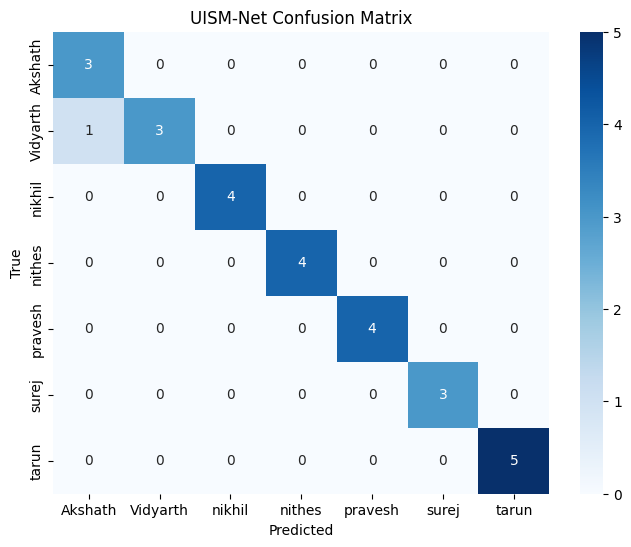

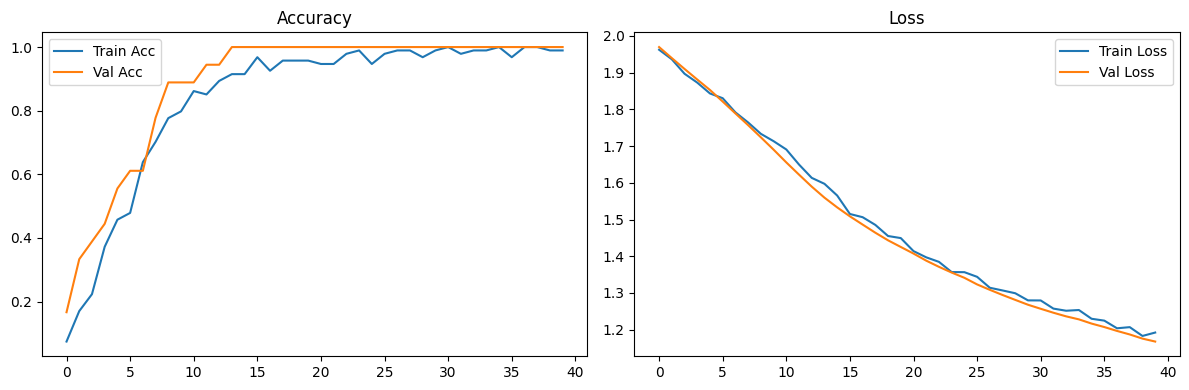

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight

TRAIN_DIR = '/content/drive/MyDrive/rgb_dataset/dataset_split/train'
VAL_DIR   = '/content/drive/MyDrive/rgb_dataset/dataset_split/val'
TEST_DIR  = '/content/drive/MyDrive/rgb_dataset/dataset_split/test'

BATCH_SIZE = 16          # smaller batch, small dataset
IMG_SIZE = (128, 128)

train_dataset = tf.keras.utils.image_dataset_from_directory(TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True, seed=42)
val_dataset   = tf.keras.utils.image_dataset_from_directory(VAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE)
test_dataset  = tf.keras.utils.image_dataset_from_directory(TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE)

class_names = train_dataset.class_names
num_classes = len(class_names)
print("Classes:", class_names)

# sanity check: how many images per split
for name, ds_dir in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]:
    import os
    for c in class_names:
        p = os.path.join(ds_dir, c)
        print(name, c, len(os.listdir(p)) if os.path.exists(p) else "MISSING")

# class weights (in case counts are uneven)
train_labels = np.concatenate([y.numpy() for _, y in train_dataset])
class_weights = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weight_dict = dict(enumerate(class_weights))

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

def build_uism_net(input_shape=(128,128,3), embedding_dim=128, num_classes=7):
    base = tf.keras.applications.MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')
    base.trainable = False  # freeze — critical for tiny datasets

    inputs = layers.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    raw_embedding = layers.Dense(embedding_dim, name="uism_embedding")(x)
    normalized_embedding = layers.Lambda(lambda v: tf.math.l2_normalize(v, axis=1),
                                          name="unit_hypersphere_embedding")(raw_embedding)
    outputs = layers.Dense(num_classes, activation='softmax', name="classification_head")(normalized_embedding)
    return models.Model(inputs, outputs, name="UISM_Net_Full")

model = build_uism_net(num_classes=num_classes)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)

history = model.fit(train_dataset, validation_data=val_dataset, epochs=40,
                     callbacks=[early_stopping, reduce_lr], class_weight=class_weight_dict)

import os
os.makedirs('/content/drive/MyDrive/rgb_dataset/saved_models', exist_ok=True)
model.save('/content/drive/MyDrive/rgb_dataset/saved_models/rgb_face_cnn_model.keras')

# ---- Evaluation ----
y_true, y_pred = [], []
for images, labels in test_dataset:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))
y_true, y_pred = np.array(y_true), np.array(y_pred)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
print(f"Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f}")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('UISM-Net Confusion Matrix')
plt.show()

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend(); plt.title('Accuracy')
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend(); plt.title('Loss')
plt.tight_layout(); plt.show()

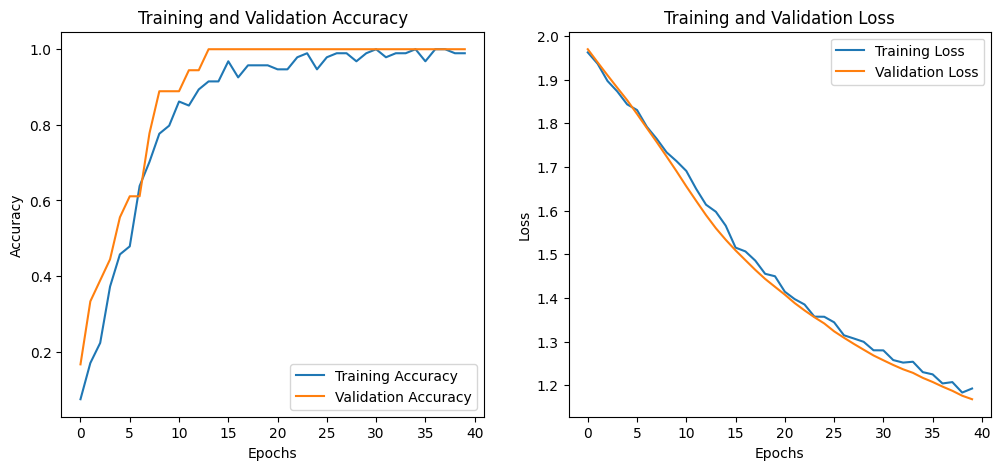

Final Training Accuracy: 98.94%
Final Validation Accuracy: 100.00%
Train-Val Accuracy Gap: -1.06%
Generalization check passed: The train and validation metrics are tracking well together.


In [ ]:
import matplotlib.pyplot as plt

# 1. Plot Training vs Validation Curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

# 2. Quantitative Overfitting Analysis (Accuracy Gap Check)
train_acc_final = acc[-1]
val_acc_final = val_acc[-1]
accuracy_gap = train_acc_final - val_acc_final

print(f"Final Training Accuracy: {train_acc_final * 100:.2f}%")
print(f"Final Validation Accuracy: {val_acc_final * 100:.2f}%")
print(f"Train-Val Accuracy Gap: {accuracy_gap * 100:.2f}%")

if accuracy_gap > 0.12:
    print("Warning: A wide gap indicates potential overfitting. Consider increasing dropout or adding data augmentation.")
else:
    print("Generalization check passed: The train and validation metrics are tracking well together.")

_IncompleteInputError: incomplete input (713818999.py, line 21)

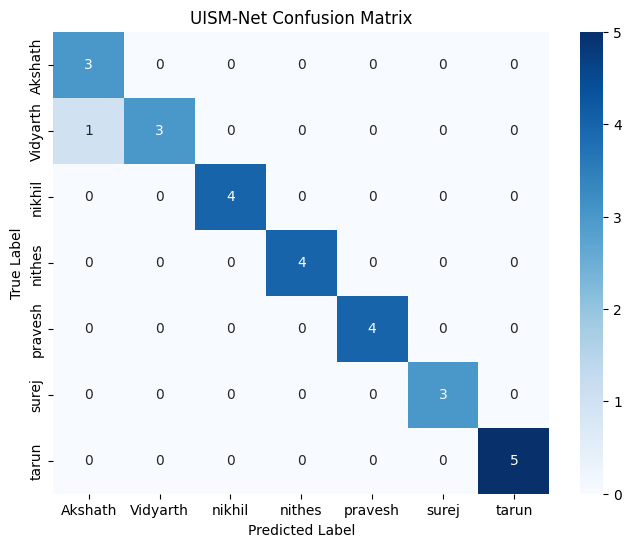

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('UISM-Net Confusion Matrix')
plt.savefig(f"{REPO_DIR}/results/confusion_matrix.png", dpi=150, bbox_inches='tight')  # BEFORE show
plt.show()

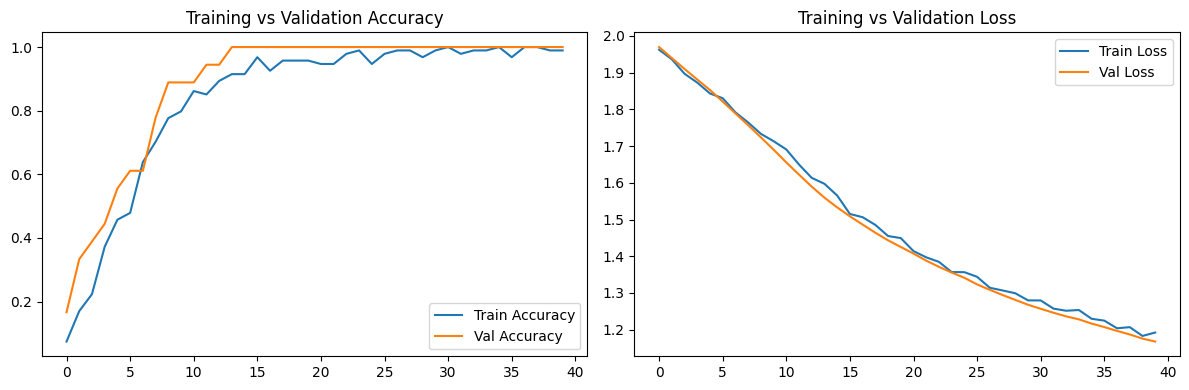

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.tight_layout()
plt.savefig(f"{REPO_DIR}/results/training_curves.png", dpi=150, bbox_inches='tight')  # BEFORE show
plt.show()

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support

report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)

best_val_acc = max(history.history['val_accuracy'])
final_train_acc = history.history['accuracy'][-1]
epochs_run = len(history.history['accuracy'])
total_test = sum(int(report_dict[c]['support']) for c in class_names)

lines = []
lines.append("# RGB Face Identification — UISM-Net")
lines.append("")
lines.append("Unified Identity-Spectral Manifold Network (UISM-Net): a 7-class face identification model that projects RGB face images onto a normalized (hyperspherical) embedding space, trained with a softmax classification head.")
lines.append("")
lines.append("## Architecture")
lines.append("")
lines.append("- **Backbone:** MobileNetV2 (ImageNet pretrained, frozen)")
lines.append("- **Input:** 128x128 RGB images")
lines.append("- **Embedding:** 128-dim dense layer, L2-normalized onto unit hypersphere")
lines.append("- **Head:** Dense softmax classifier (used only during training)")
lines.append("- **Augmentation:** Random horizontal flip, rotation, zoom")
lines.append("- **Classes (" + str(len(class_names)) + "):** " + ", ".join(class_names))
lines.append("")
lines.append("## Training Setup")
lines.append("")
lines.append("- Optimizer: Adam (lr=1e-4, ReduceLROnPlateau)")
lines.append("- Loss: Sparse categorical crossentropy")
lines.append("- Class weights: balanced")
lines.append("- Early stopping on val_loss (patience=8)")
lines.append("- Epochs run: " + str(epochs_run))
lines.append("")
lines.append("## Results")
lines.append("")
lines.append("- **Test Accuracy:** " + f"{acc:.3f}")
lines.append("- **Weighted Precision:** " + f"{prec:.3f}")
lines.append("- **Weighted Recall:** " + f"{rec:.3f}")
lines.append("- **Weighted F1-score:** " + f"{f1:.3f}")
lines.append("- **Best Validation Accuracy:** " + f"{best_val_acc:.3f}")
lines.append("- **Final Training Accuracy:** " + f"{final_train_acc:.3f}")
lines.append("")
lines.append("### Per-class metrics")
lines.append("")
lines.append("| Class | Precision | Recall | F1-score | Support |")
lines.append("|---|---|---|---|---|")
for cls in class_names:
    m = report_dict[cls]
    row = "| " + cls + " | " + f"{m['precision']:.2f}" + " | " + f"{m['recall']:.2f}" + " | " + f"{m['f1-score']:.2f}" + " | " + str(int(m['support'])) + " |"
    lines.append(row)
lines.append("")
lines.append("### Confusion Matrix")
lines.append("")
lines.append("![Confusion Matrix](results/confusion_matrix.png)")
lines.append("")
lines.append("### Training Curves")
lines.append("")
lines.append("![Accuracy and Loss](results/training_curves.png)")
lines.append("")
lines.append("## Repo Structure")
lines.append("")
lines.append("- saved_models/rgb_face_cnn_model.keras — trained model")
lines.append("- results/confusion_matrix.png — evaluation confusion matrix")
lines.append("- results/training_curves.png — accuracy/loss curves")
lines.append("- requirements.txt — dependencies")
lines.append("")
lines.append("## Usage")
lines.append("")
lines.append("```python")
lines.append("import tensorflow as tf")
lines.append('model = tf.keras.models.load_model("saved_models/rgb_face_cnn_model.keras")')
lines.append("```")
lines.append("")
lines.append("## Notes")
lines.append("")
lines.append("- Dataset is small (~" + str(total_test) + " test images across " + str(len(class_names)) + " classes); metrics should be treated as indicative, not statistically robust.")
lines.append("- Consider expanding to 50+ images per class for more reliable evaluation.")

readme_content = "\n".join(lines)

with open(f"{REPO_DIR}/README.md", "w") as f:
    f.write(readme_content)

print("README.md generated (" + str(len(lines)) + " lines).")

README.md generated (68 lines).


In [ ]:
with open(f"{REPO_DIR}/README.md") as f:
    print(f.read())

# RGB Face Identification — UISM-Net

Unified Identity-Spectral Manifold Network (UISM-Net): a 7-class face identification model that projects RGB face images onto a normalized (hyperspherical) embedding space, trained with a softmax classification head.

## Architecture

- **Backbone:** MobileNetV2 (ImageNet pretrained, frozen)
- **Input:** 128x128 RGB images
- **Embedding:** 128-dim dense layer, L2-normalized onto unit hypersphere
- **Head:** Dense softmax classifier (used only during training)
- **Augmentation:** Random horizontal flip, rotation, zoom
- **Classes (7):** Akshath, Vidyarth, nikhil, nithes, pravesh, surej, tarun

## Training Setup

- Optimizer: Adam (lr=1e-4, ReduceLROnPlateau)
- Loss: Sparse categorical crossentropy
- Class weights: balanced
- Early stopping on val_loss (patience=8)
- Epochs run: 40

## Results

- **Test Accuracy:** 0.963
- **Weighted Precision:** 0.972
- **Weighted Recall:** 0.963
- **Weighted F1-score:** 0.963
- **Best Validation Accuracy:** 1.000
-

In [ ]:
import os, shutil

GITHUB_TOKEN = os.getenv("GITHUB_TOKEN", "YOUR_GITHUB_TOKEN")  # paste your token here
REPO_URL = "https://github.com/Nikhil-2005-beep/RGB-Face-Identification.git"
REPO_DIR = "/content/repo"

# Clone (only needed once per session)
if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}

os.makedirs(f"{REPO_DIR}/saved_models", exist_ok=True)
os.makedirs(f"{REPO_DIR}/results", exist_ok=True)

# Copy model + plots
shutil.copy('/content/drive/MyDrive/rgb_dataset/saved_models/rgb_face_cnn_model.keras',
            f"{REPO_DIR}/saved_models/rgb_face_cnn_model.keras")

with open(f"{REPO_DIR}/requirements.txt", "w") as f:
    f.write("tensorflow\nscikit-learn\nmatplotlib\nseaborn\nnumpy\n")

%cd {REPO_DIR}
!git config user.email "nikhilkaviram1125@gmail.com"
!git config user.name "Nikhil-2005-beep"
!git add -A
!git commit -m "Add trained UISM-Net model and results"
!git push https://{GITHUB_TOKEN}@github.com/Nikhil-2005-beep/RGB-Face-Identification.git main

Using augmented train set: /content/drive/MyDrive/rgb_dataset/dataset_split/train_augmented

LBP + SVM — Acc: 0.889 | Prec: 0.923 | Rec: 0.889 | F1: 0.892
              precision    recall  f1-score   support

     Akshath       0.75      1.00      0.86         3
    Vidyarth       1.00      0.75      0.86         4
      nikhil       1.00      1.00      1.00         4
      nithes       0.67      1.00      0.80         4
     pravesh       1.00      0.75      0.86         4
       surej       1.00      1.00      1.00         3
       tarun       1.00      0.80      0.89         5

    accuracy                           0.89        27
   macro avg       0.92      0.90      0.89        27
weighted avg       0.92      0.89      0.89        27


HOG + SVM — Acc: 1.000 | Prec: 1.000 | Rec: 1.000 | F1: 1.000
              precision    recall  f1-score   support

     Akshath       1.00      1.00      1.00         3
    Vidyarth       1.00      1.00      1.00         4
      nikhil       1.0

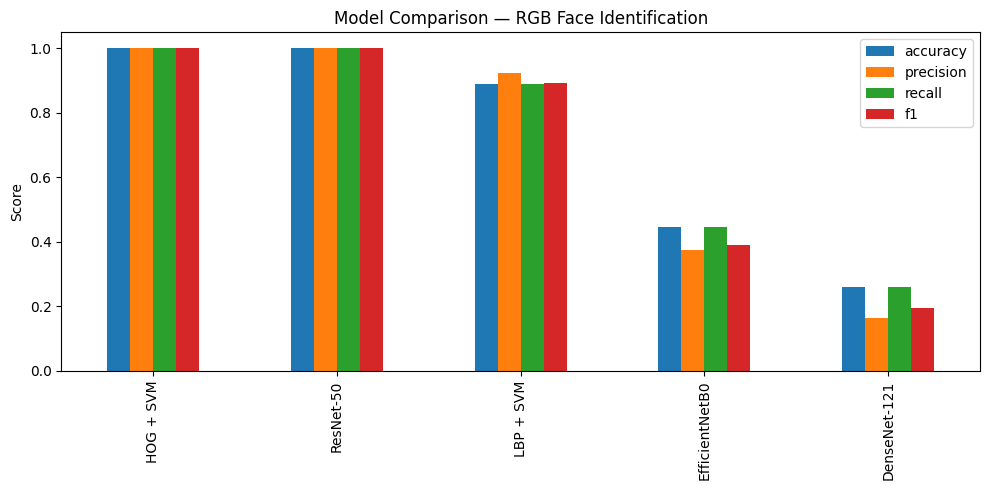


Saved model_comparison.png and model_comparison.csv to results/


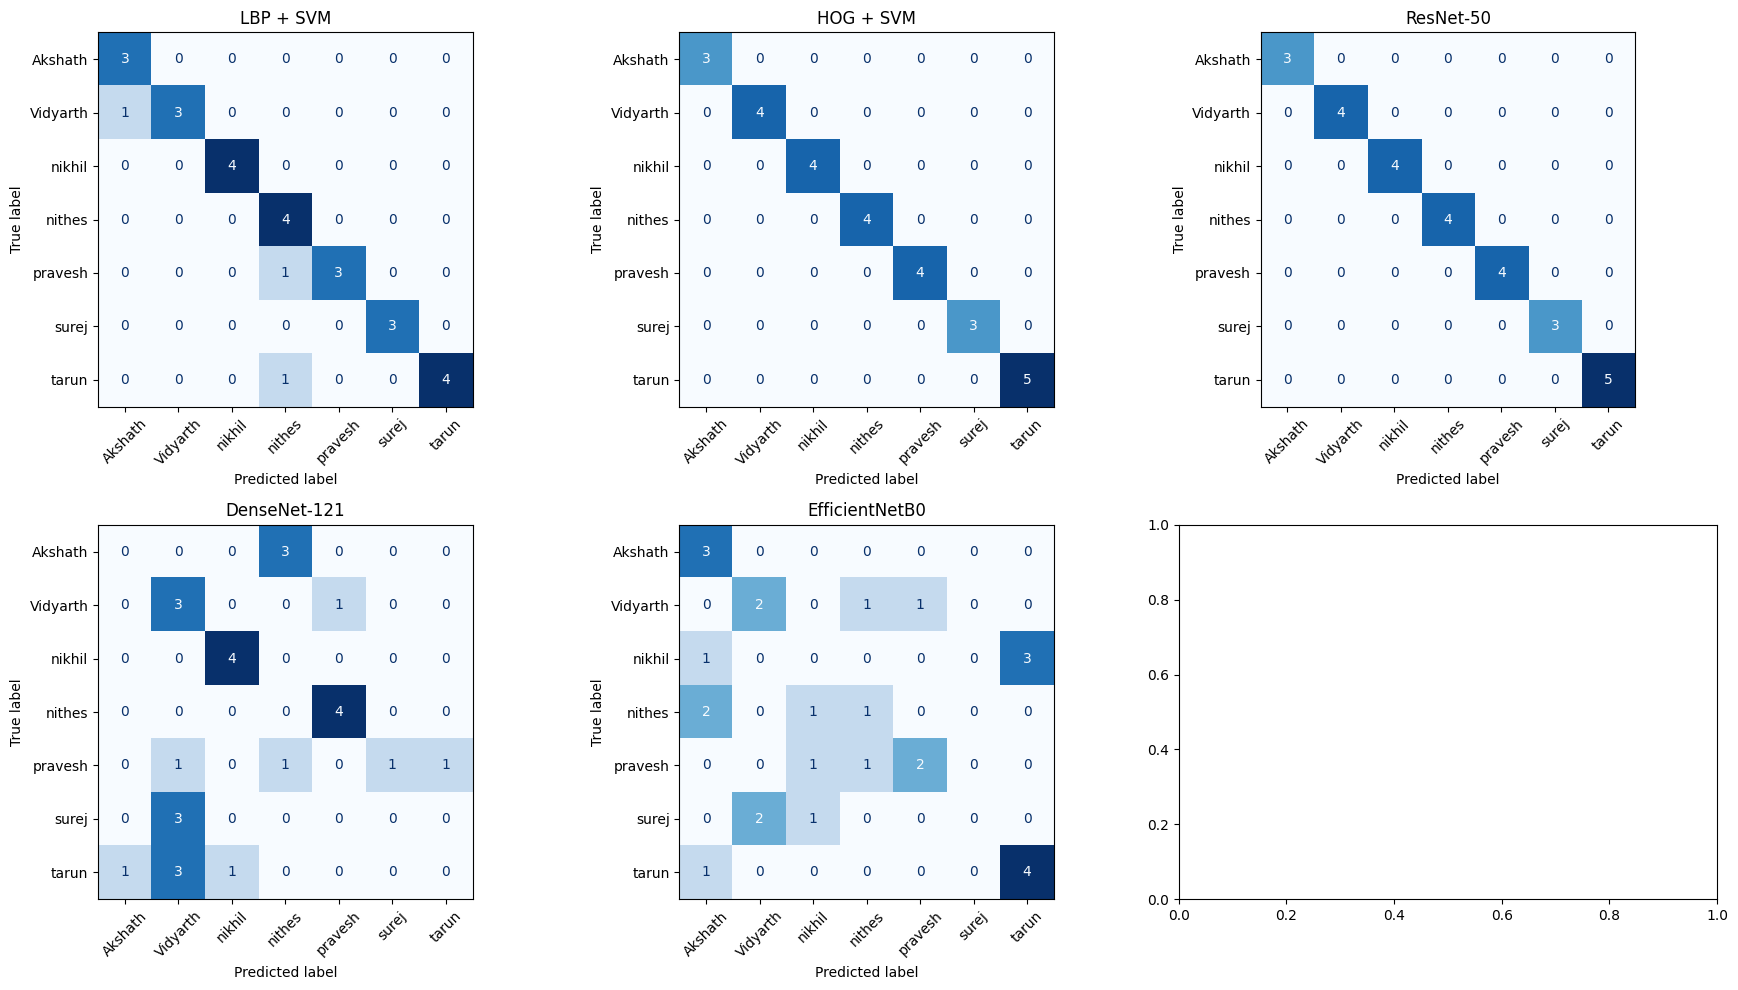

Saved all_confusion_matrices.png to results/


In [ ]:
# ================================================================
# RGB FACE IDENTIFICATION — MODEL COMPARISON SCRIPT (+ CONFUSION MATRICES)
# Trains 5 baseline/SOTA models and compares against proposed UISM-Net
# ================================================================

import numpy as np, os, cv2
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
from skimage.feature import local_binary_pattern, hog
import tensorflow as tf
from tensorflow.keras import layers, models

# ---------------- Paths & constants ----------------
TRAIN_DIR = '/content/drive/MyDrive/rgb_dataset/dataset_split/train'
VAL_DIR   = '/content/drive/MyDrive/rgb_dataset/dataset_split/val'
TEST_DIR  = '/content/drive/MyDrive/rgb_dataset/dataset_split/test'
IMG_SIZE = (128, 128)
class_names = sorted(os.listdir(TRAIN_DIR))
num_classes = len(class_names)

REPO_DIR = "/content/repo"  # must already be cloned from earlier steps
os.makedirs(f"{REPO_DIR}/results", exist_ok=True)

results = {}      # accuracy/precision/recall/f1 for every model
preds_store = {}  # (y_true, y_pred) for every model — used for confusion matrices

# ================================================================
# STEP 0: DATA SYNTHESIS — grow tiny train set via crops/flips
# Only applied to TRAIN folder — never val/test, to avoid leakage
# ================================================================
AUG_TRAIN_DIR = '/content/drive/MyDrive/rgb_dataset/dataset_split/train_augmented'

def synthesize_crops(src_dir, dst_dir, n_aug=4):
    os.makedirs(dst_dir, exist_ok=True)
    for cls in os.listdir(src_dir):
        os.makedirs(f"{dst_dir}/{cls}", exist_ok=True)
        for fname in os.listdir(f"{src_dir}/{cls}"):
            img = cv2.imread(f"{src_dir}/{cls}/{fname}")
            h, w = img.shape[:2]
            cv2.imwrite(f"{dst_dir}/{cls}/orig_{fname}", img)  # keep original
            for i in range(n_aug):
                crop_ratio = np.random.uniform(0.8, 1.0)  # random crop 80-100% of frame
                ch, cw = int(h * crop_ratio), int(w * crop_ratio)
                y0 = np.random.randint(0, h - ch + 1)
                x0 = np.random.randint(0, w - cw + 1)
                crop = cv2.resize(img[y0:y0+ch, x0:x0+cw], (w, h))
                if np.random.rand() > 0.5:
                    crop = cv2.flip(crop, 1)  # random horizontal flip
                cv2.imwrite(f"{dst_dir}/{cls}/aug{i}_{fname}", crop)

if not os.path.exists(AUG_TRAIN_DIR):  # only synthesize once
    synthesize_crops(TRAIN_DIR, AUG_TRAIN_DIR, n_aug=4)  # 1 original + 4 crops = 5x train data
print("Using augmented train set:", AUG_TRAIN_DIR)

# ---------------- Helper: load raw images as numpy arrays (for LBP/HOG) ----------------
def load_raw(folder):
    X, y = [], []
    for idx, cls in enumerate(class_names):
        cls_dir = os.path.join(folder, cls)
        for fname in os.listdir(cls_dir):
            img = cv2.imread(os.path.join(cls_dir, fname))
            img = cv2.resize(img, IMG_SIZE)
            X.append(img)
            y.append(idx)
    return np.array(X), np.array(y)

X_train_raw, y_train = load_raw(AUG_TRAIN_DIR)  # uses synthesized data
X_val_raw, y_val     = load_raw(VAL_DIR)
X_test_raw, y_test   = load_raw(TEST_DIR)

# ---------------- Helper: record metrics + predictions for any model ----------------
def record(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    results[name] = {"accuracy": acc, "precision": p, "recall": r, "f1": f1}
    preds_store[name] = (np.array(y_true), np.array(y_pred))  # NEW — for confusion matrices
    print(f"\n{name} — Acc: {acc:.3f} | Prec: {p:.3f} | Rec: {r:.3f} | F1: {f1:.3f}")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# ================================================================
# MODEL 1: LBP (Local Binary Pattern) + SVM — classical texture baseline
# ================================================================
def extract_lbp(images, P=8, R=1):
    feats = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        lbp = local_binary_pattern(gray, P, R, method='uniform')
        hist, _ = np.histogram(lbp, bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype('float') / (hist.sum() + 1e-6)
        feats.append(hist)
    return np.array(feats)

X_train_lbp = extract_lbp(X_train_raw)
X_val_lbp   = extract_lbp(X_val_raw)
X_test_lbp  = extract_lbp(X_test_raw)

svm_lbp = SVC(kernel='rbf', C=10, gamma='scale')
svm_lbp.fit(np.vstack([X_train_lbp, X_val_lbp]), np.hstack([y_train, y_val]))
record("LBP + SVM", y_test, svm_lbp.predict(X_test_lbp))

# ================================================================
# MODEL 2: HOG (Histogram of Oriented Gradients) + SVM — classical shape baseline
# ================================================================
def extract_hog(images):
    feats = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        feat = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
        feats.append(feat)
    return np.array(feats)

X_train_hog = extract_hog(X_train_raw)
X_val_hog   = extract_hog(X_val_raw)
X_test_hog  = extract_hog(X_test_raw)

svm_hog = SVC(kernel='rbf', C=10, gamma='scale')
svm_hog.fit(np.vstack([X_train_hog, X_val_hog]), np.hstack([y_train, y_val]))
record("HOG + SVM", y_test, svm_hog.predict(X_test_hog))

# ================================================================
# Shared tf.data pipelines for deep models (uses augmented train dir)
# ================================================================
train_ds = tf.keras.utils.image_dataset_from_directory(AUG_TRAIN_DIR, image_size=IMG_SIZE, batch_size=16, shuffle=True, seed=42)
val_ds   = tf.keras.utils.image_dataset_from_directory(VAL_DIR, image_size=IMG_SIZE, batch_size=16)
test_ds  = tf.keras.utils.image_dataset_from_directory(TEST_DIR, image_size=IMG_SIZE, batch_size=16, shuffle=False)

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

# Helper to build a frozen-backbone transfer learning model
def build_transfer_model(backbone_fn, preprocess_fn, name, input_shape=(128, 128, 3)):
    base = backbone_fn(input_shape=input_shape, include_top=False, weights='imagenet')
    base.trainable = False  # freeze backbone — dataset too small to fine-tune safely
    inputs = layers.Input(shape=input_shape)
    x = preprocess_fn(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    m = models.Model(inputs, outputs, name=name)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

# ================================================================
# MODEL 3, 4, 5: ResNet-50, DenseNet-121, EfficientNetB0
# All built into tf.keras.applications — no external installs, no version breakage
# ================================================================
for backbone_fn, preprocess_fn, name in [
    (tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input, "ResNet-50"),
    (tf.keras.applications.DenseNet121, tf.keras.applications.densenet.preprocess_input, "DenseNet-121"),
    (tf.keras.applications.EfficientNetB0, tf.keras.applications.efficientnet.preprocess_input, "EfficientNetB0"),
]:
    model = build_transfer_model(backbone_fn, preprocess_fn, name)
    model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=[early_stop], verbose=0)
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    y_true = np.concatenate([y for _, y in test_ds])
    record(name, y_true, y_pred)

# ================================================================
# PROPOSED MODEL: UISM-Net — load full saved model directly
# ================================================================

# ================================================================
# COMPARISON TABLE + CHART
# ================================================================
df = pd.DataFrame(results).T.sort_values("f1", ascending=False)
print("\n=== FINAL MODEL COMPARISON ===")
print(df.round(3))

df.plot(kind='bar', figsize=(10, 5), title="Model Comparison — RGB Face Identification")
plt.ylabel("Score")
plt.tight_layout()
plt.savefig(f"{REPO_DIR}/results/model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

df.to_csv(f"{REPO_DIR}/results/model_comparison.csv")
print("\nSaved model_comparison.png and model_comparison.csv to results/")

# ================================================================
# CONFUSION MATRICES — one per model, all 6 in a single grid
# ================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, (yt, yp)) in zip(axes.flat, preds_store.items()):
    cm = confusion_matrix(yt, yp)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(f"{REPO_DIR}/results/all_confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved all_confusion_matrices.png to results/")